# Generate Particle ID

This notebook is used to select the particle group (particle ID) from the estimate phase from Spyral. The notebook is adapted to use the `attpc_analysis` classes. 

In [1]:
from spyral_utils.plot import CutHandler, Histogrammer
from spyral_utils.plot.cut import MultiPolygonSelector
from spyral_utils.nuclear import NuclearDataMap
from spyral_utils.nuclear.particle_id import serialize_particle_id, ParticleID,  deserialize_particle_id
from spyral.core.constants import DEG2RAD

import polars as pl
import matplotlib.pyplot as plt

from pathlib import Path
import numpy as np
from json import load
%matplotlib widget


# This is for the meantime -------------------------------------------------------
# The final motivation is to make it pip installeable 
import sys
src_path = Path.cwd().parents[1]
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
# --------------------------------------------------------------------------------
from attpc_analysis.src.load.io import  RunEstimationDataLoader
from matplotlib import cm
colormap=cm.get_cmap('rainbow')

RAD2DEG = 1.0/DEG2RAD

/tmp/ipykernel_45918/3700379180.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap=cm.get_cmap('rainbow')


In [2]:
# Set some parameters
nuclear_map = NuclearDataMap()
# Read the json file 
exp_tag = "a2066"
pid_x_axis = "sqrt_dEdx" # This is the PID x-axis, matching a column name in the estimation dataframe
pid_y_axis = "brho" # This is the PID y-axis, matching a column name in the estimation dataframe
show_preexisting_gates = True 
list_pids = ["hydrogen_1.json", "hydrogen_2.json", "hydrogen_3_t.json", "helium_3.json", "helium_4.json"]

path_to_config = Path(f"../../notebooks/input_parameters/{exp_tag}.json")
with open(path_to_config,"r") as json_file:
    json_data = load(json_file)
    # Get keys from json and use them as their variables 
    workspace_path = Path(json_data["workspace_path"])
    trace_path = Path(json_data["trace_path"])
    target_material_path = Path(json_data["target_path"])
    run_min = json_data["run_min"]
    run_max = json_data["run_max"]
    runs_to_skip = json_data["runs_to_skip"]
    ejectile = nuclear_map.get_data(json_data["ejectile"][0], json_data["ejectile"][1])
    projectile = nuclear_map.get_data(json_data["projectile"][0], json_data["projectile"][1])
    target = nuclear_map.get_data(json_data["target"][0], json_data["target"][1])
    ic_pressure = json_data["ic_pressure"]
    beam_energy = json_data["beam_energy"]
    ic_min_val = json_data["ic_min_val"]
    ic_max_val = json_data["ic_max_val"]

estimation_result_path = workspace_path / "Estimation"

In [3]:
deuterons = pl.read_csv("./high_energy_deuterons.csv")

In [4]:
grammer = Histogrammer()
handler = CutHandler()
grammer.add_hist2d("particle_id", (400, 400), ((-10.0, 200.0), (-0.1, 3.0))) # Plot of particle ID. Depending on your axes, you may need to change these limits, binning
grammer.add_hist1d("ion_chamber", 2026, (0.0, 2026.0))
grammer.add_hist2d("kinematics", (720, 400), ((0.0, 180.0), (0.0, 3.0))) # Plot of polar angle vs. Brho (kinematics)
grammer.add_hist2d("vertex_z_brho", (200, 200), ((-100.0, 1100.0), (0.0, 3.0))) 

# grammer.add_hist2d("particle_id", (100, 100), ((-10.0, 200.0), (-0.1, 3.0))) # Plot of particle ID. Depending on your axes, you may need to change these limits, binning
# grammer.add_hist1d("ion_chamber", 2026, (0.0, 2026.0))
# grammer.add_hist2d("kinematics", (330, 100), ((0.0, 180.0), (0.0, 3.0))) # Plot of polar angle vs. Brho (kinematics)
# grammer.add_hist2d("vertex_z_brho", (50, 50), ((-100.0, 1100.0), (0.0, 3.0))) 

grammer.add_hist2d("arclength", (500, 500), ((-0.1,100.0), (-0.1, 1000.0))) 
# Load class with general details of the runs
empty_files = []
estimation_data = RunEstimationDataLoader(
                estimation_result_path=estimation_result_path, 
                empty_files = empty_files
                )

arclength = np.empty(0,float)
sqrtdedx = np.empty(0,float)

for run in range(run_min, run_max+1):
    # load data
    df = estimation_data.load_estimation(run)
    # print("here 1")
    if df is None or df.shape==(0,0): continue 
    # Add histograms without any filter 
    grammer.fill_hist1d('ion_chamber', df.unique(subset=['orig_event']).select('ic_amplitude').to_numpy())
    # print("here")
    #------------------------------------------------------------------------------
    # Insert specific filters into the dataframe 
    # (Here)
    # Example
    df = df.filter((pl.col('ic_amplitude') > ic_min_val) & (pl.col('ic_amplitude') < ic_max_val))
    df = df.filter(pl.col("ic_multiplicity")==1)
    # df = df.filter((pl.col("sqrt_dEdx")>55)&(pl.col("sqrt_dEdx")<85)&(pl.col("arclength")<200)&(pl.col("arclength")>50)&(pl.col("brho")<0.225))
    df_dcopy = deuterons.clone()
    df_dcopy = deuterons.filter(pl.col("run")==run)
    events_high_energy = df_dcopy.select("event").to_numpy().flatten()
    # df = df.filter(pl.col("event").is_in(events_high_energy))
    #------------------------------------------------------------------------------  
    arclength = np.append(arclength, df.select("arclength").to_numpy().flatten())
    sqrtdedx = np.append(sqrtdedx, df.select("sqrt_dEdx").to_numpy().flatten())
    # Add histograms 
    grammer.fill_hist2d('particle_id', df.select(pid_x_axis).to_numpy(), df.select(pid_y_axis).to_numpy())
    grammer.fill_hist2d('kinematics', df.select('polar').to_numpy() * RAD2DEG, df.select('brho').to_numpy())
    grammer.fill_hist2d('vertex_z_brho', df.select('vertex_z').to_numpy(),df.select('brho').to_numpy())

    grammer.fill_hist2d("arclength",sqrtdedx,arclength)
    # Delete dataframe and collect to avoid open threads
    df = None

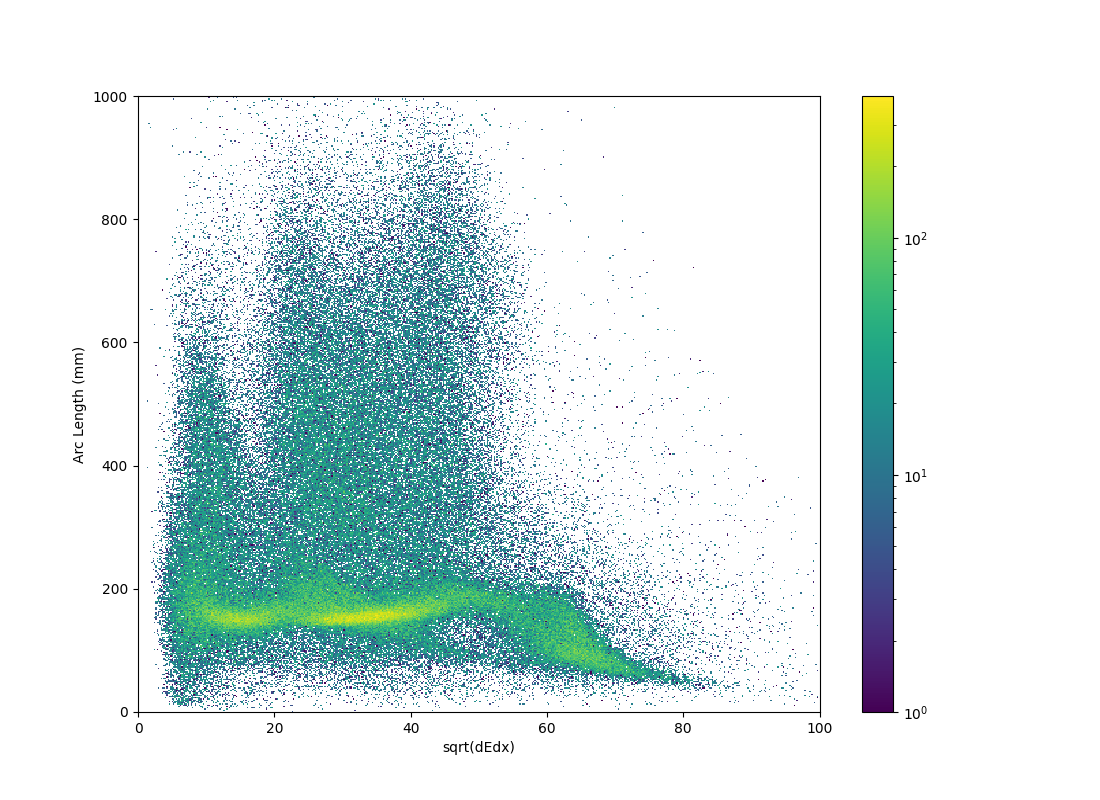

In [5]:
kine = grammer.get_hist2d("arclength")
fig, ax = plt.subplots(1,1)
mesh = ax.pcolormesh(kine.x_bins, kine.y_bins, kine.counts, norm="log")
fig.colorbar(mesh, ax=ax)
# ax.set_title()
ax.set_ylabel("Arc Length (mm)")
ax.set_xlabel("sqrt(dEdx)")
fig.set_figheight(8.0)
fig.set_figwidth(11.0)
# ax.set_xlim([90,180])
fig.savefig("delete1.png")

/tmp/ipykernel_28468/2144256895.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


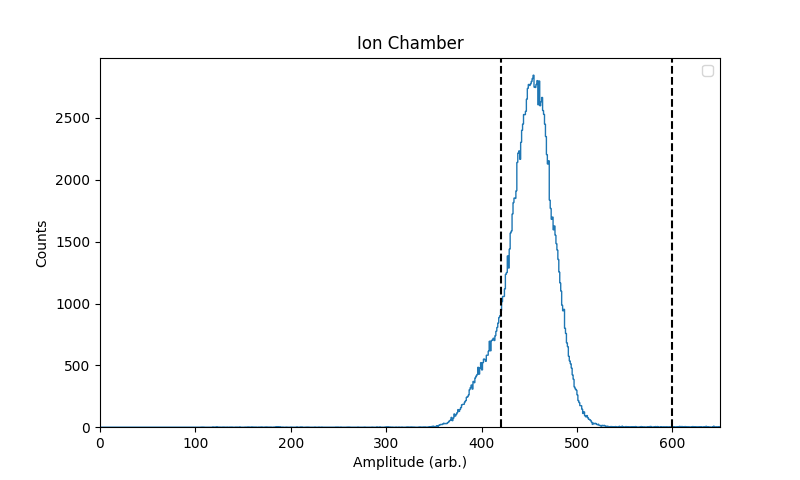

In [37]:
ic = grammer.get_hist1d("ion_chamber")
fig, ax = plt.subplots(1,1)
ax.axvline(ic_min_val,linestyle='--',color='black')
ax.axvline(ic_max_val,linestyle='--',color='black')
ax.stairs(ic.counts, edges=ic.bins)
ax.set_title("Ion Chamber")
ax.set_xlabel("Amplitude (arb.)")
ax.set_ylabel("Counts")
fig.set_figwidth(8.0)
ax.set_xlim([0,650]) # this dataset
ax.legend()
fig.savefig("delete1.png")

/tmp/ipykernel_45918/3703653808.py:9: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  cbar.ax.set_ylim(0,380)


379.99999999999994


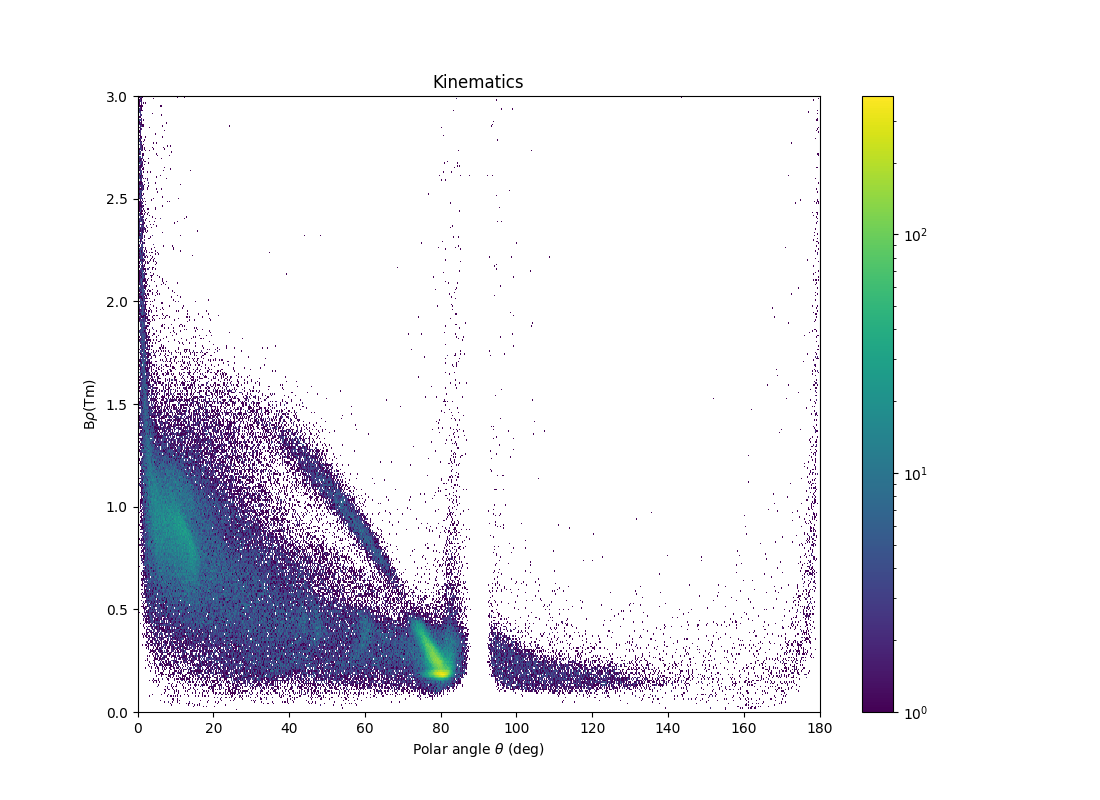

In [7]:
from matplotlib.colors import LogNorm
kine = grammer.get_hist2d("kinematics")
fig, ax = plt.subplots(1,1)
mesh = ax.pcolormesh(kine.x_bins, kine.y_bins, kine.counts, 
                    #  norm="log", 
                     norm=LogNorm(vmin=1, vmax=380)
                     )
cbar = fig.colorbar(mesh, ax=ax)
cbar.ax.set_ylim(0,380)
print(cbar.vmax)
ax.set_title("Kinematics")
ax.set_xlabel("Polar angle $\\theta$ (deg)")

ax.set_ylabel("B$\\rho$(Tm)")
fig.set_figheight(8.0)
fig.set_figwidth(11.0)
# ax.set_xlim([90,180])
fig.savefig("delete1.png")


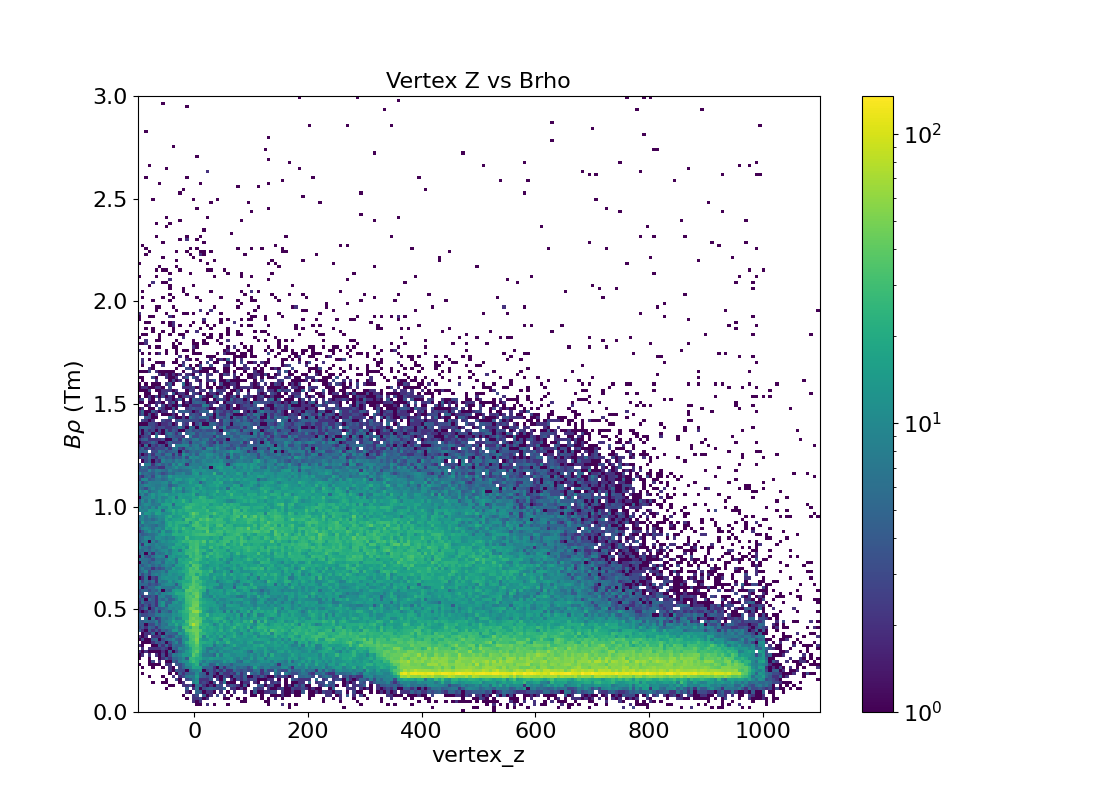

In [ ]:
vertex_hist = grammer.get_hist2d("vertex_z_brho")
fig, ax = plt.subplots(1,1)
kwargs = {"fontsize": 16}
mesh = ax.pcolormesh(vertex_hist.x_bins, vertex_hist.y_bins, vertex_hist.counts, 
                     norm="log")
cbar = fig.colorbar(mesh, ax=ax)
cbar.ax.tick_params(labelsize=16)

ax.set_title("Vertex Z vs Brho", **kwargs)
ax.set_xlabel(r"vertex_z",**kwargs)

ax.set_ylabel(r"$B\rho$ (Tm)",**kwargs)
ax.tick_params(labelsize=16)

fig.set_figheight(8.0)
fig.set_figwidth(11.0)
fig.savefig("delete1.png")

/tmp/ipykernel_45918/1547668401.py:12: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  cbar.ax.set_ylim(0, 250)


Counts: 221681


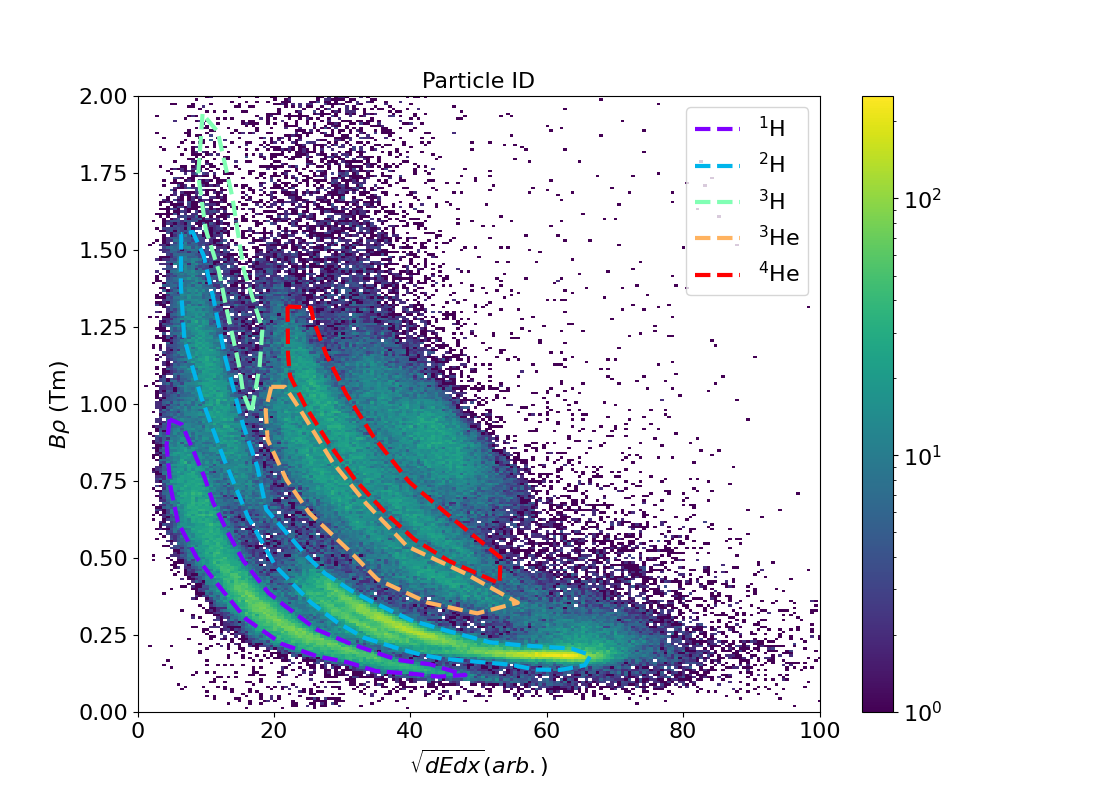

In [8]:
pid_hist = grammer.get_hist2d("particle_id")
fig, ax = plt.subplots(1,1)
kwargs = {"fontsize": 16}
# _ = PolygonSelector(ax, handler.mpl_on_select)
_ = MultiPolygonSelector(ax, handler)

mesh = ax.pcolormesh(pid_hist.x_bins, pid_hist.y_bins, pid_hist.counts, 
                    #  norm="log",
                     norm=LogNorm(vmin=1, vmax=250))
cbar = fig.colorbar(mesh, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.ax.set_ylim(0, 250) 

# If you wanna see the old gates 
pid_path = Path("/mnt/analysis/argonne2023/ramirezc/a2066/workspace_369_tune_pad/")
if show_preexisting_gates: 
    colors = colormap(np.linspace(0,1,len(list_pids)))
    for i in range(len(list_pids)):
        # pid= deserialize_particle_id(workspace_path/list_pids[i], nuclear_map)
        pid= deserialize_particle_id(pid_path/list_pids[i], nuclear_map)
        x_array,y_array = [],[]
        for x,y in pid.cut.get_vertices():
            x_array.append(x)
            y_array.append(y)
        ax.plot(x_array,y_array,linestyle='--', linewidth=3,color=colors[i],label=pid.nucleus.get_latex_rep())

ax.set_title("Particle ID", **kwargs)
ax.set_xlabel(r"$\sqrt{dEdx} (arb.)$",**kwargs)
ax.set_ylabel(r"$B\rho$ (Tm)",**kwargs)
ax.tick_params(labelsize=16)
fig.set_figheight(8.0)
fig.set_figwidth(11.0)
print(f"Counts: {np.sum(pid_hist.counts):0.0f}")
ax.set_xlim([0,100])
ax.set_ylim([0,2])
ax.legend(fontsize=16)
fig.savefig("delete1.png")
# 115492 new direction method

In [ ]:
ax.figure

In [ ]:
# cut_0 = proton

np.float64(244.0000000000001)

In [10]:
# this way you can see how many cuts you've created
handler.cuts

{'cut_0': <spyral_utils.plot.cut.Cut2D at 0x7efbed346120>,
 'cut_1': <spyral_utils.plot.cut.Cut2D at 0x7efab668d640>,
 'cut_2': <spyral_utils.plot.cut.Cut2D at 0x7efbed3a2930>,
 'cut_3': <spyral_utils.plot.cut.Cut2D at 0x7efc0d309d30>}

In [24]:
# Set these!
pid_name = "blob" # name given to PID
pid_z = 1 # atomic number
pid_a = 1 # mass number
nucleus = nuclear_map.get_data(pid_z, pid_a)
pid_path = workspace_path / f"{pid_name}.json" # Path to which we will write our PID

# If you've made multiple cuts, you'll want to change the name used here. 
# Cuts are automatically named in the order they were made (first cut is cut_0, second cut_1, etc.)
cut = handler.cuts["cut_3"]
cut.name = pid_name # give it our custom name
cut.x_axis = pid_x_axis # specify our axes
cut.y_axis = pid_y_axis
pid = ParticleID(cut, nucleus)
# Save our pid
# serialize_particle_id(pid_path, pid) # comment out if you do not want to override new info 


In [25]:
grammer.add_hist2d("particle_id_gated", (400, 400), ((-10.0, 200.0), (0.0, 3.0))) # Plot of dEdx vs. Brho (particle ID), gated on PID
grammer.add_hist2d("kinematics_gated", (720, 400), ((0.0, 180.0), (0.0, 3.0))) # Plot of polar angle vs. Brho (kinematics), gated on PID
grammer.add_hist2d("arclength_gated", (500, 500), ((-0.1,100.0), (-0.1, 1000.0))) 

for run in range(run_min, run_max+1):
    df = estimation_data.load_estimation(run)
    if df is None or df.shape==(0,0): continue 
    #------------------------------------------------------------------------------
    # Insert specific filters into the dataframe 
    # (Here)
    # Example
    df = df.filter((pl.col('ic_amplitude') > ic_min_val) & (pl.col('ic_amplitude') < ic_max_val))
    df = df.filter(pl.struct([pid_x_axis, pid_y_axis]).map_batches(pid.cut.is_cols_inside)) # apply PID
    df = df.filter(pl.col("ic_multiplicity")==1)
    #------------------------------------------------------------------------------  
    grammer.fill_hist2d('particle_id_gated', df.select(pid_x_axis).to_numpy(), df.select(pid_y_axis).to_numpy())
    grammer.fill_hist2d('kinematics_gated', df.select('polar').to_numpy() * RAD2DEG, df.select('brho').to_numpy())


    grammer.fill_hist2d("arclength_gated",df.select(pid_x_axis).to_numpy(),df.select("arclength").to_numpy())
    # Delete dataframe
    df = None

Overwriting histogram named particle_id_gated in Histogrammer.add_histogram!
Overwriting histogram named kinematics_gated in Histogrammer.add_histogram!
Overwriting histogram named arclength_gated in Histogrammer.add_histogram!


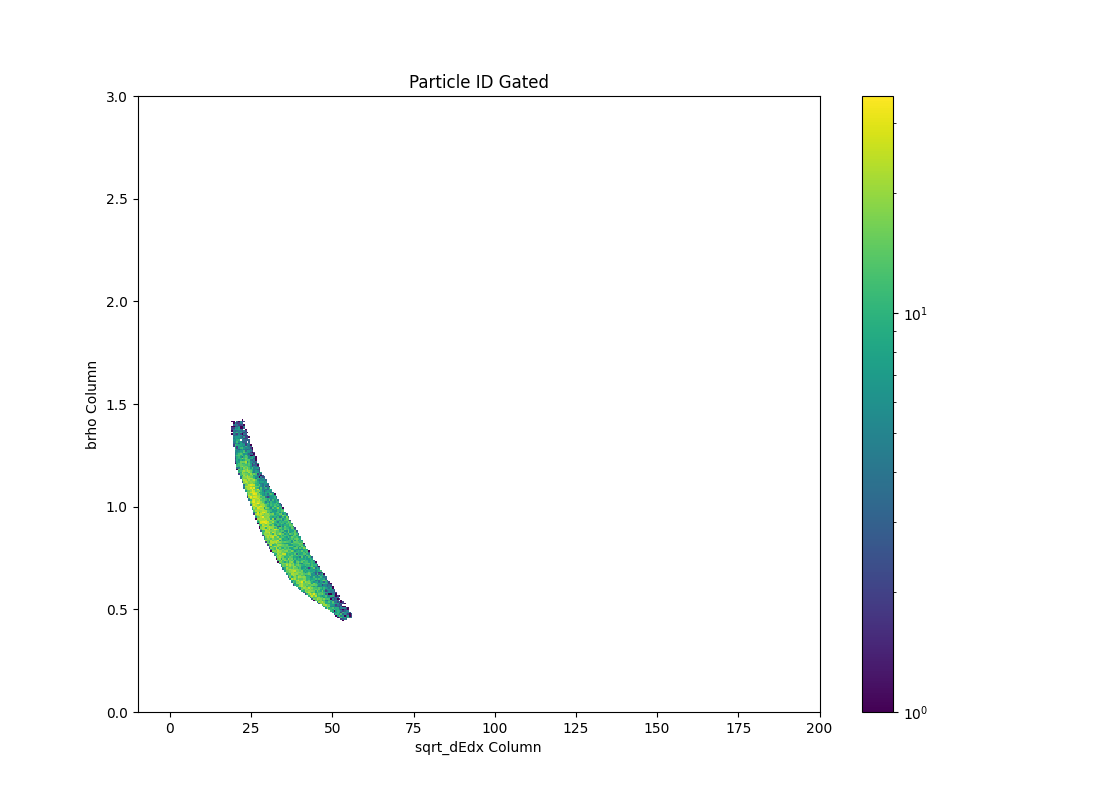

In [26]:
pid_gated = grammer.get_hist2d("particle_id_gated")
fig, ax = plt.subplots(1,1)
mesh = ax.pcolormesh(pid_gated.x_bins, pid_gated.y_bins, pid_gated.counts, norm="log")
fig.colorbar(mesh, ax=ax)
ax.set_title("Particle ID Gated")
ax.set_xlabel(f"{pid_x_axis} Column")
ax.set_ylabel(f"{pid_y_axis} Column")
fig.set_figheight(8.0)
fig.set_figwidth(11.0)

Counts:  24459.0


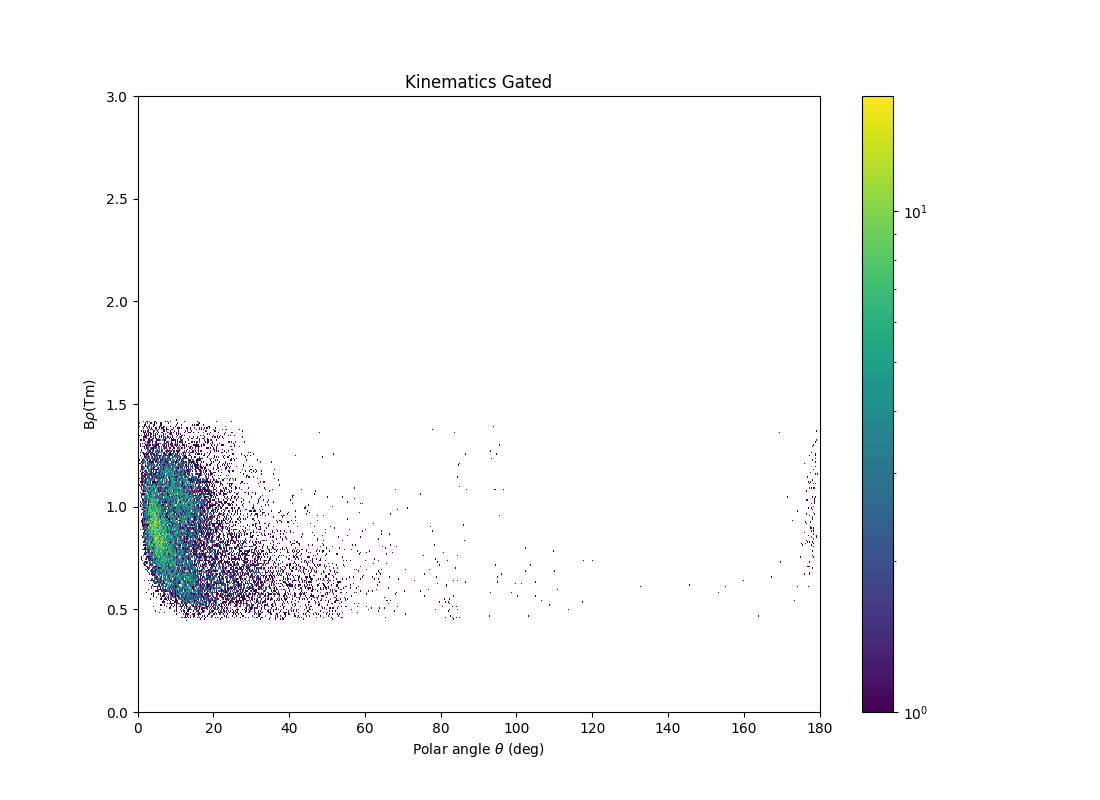

In [27]:
kine_gated = grammer.get_hist2d("kinematics_gated")
fig, ax = plt.subplots(1,1)
mesh = ax.pcolormesh(kine_gated.x_bins, kine_gated.y_bins, kine_gated.counts, norm="log")
fig.colorbar(mesh, ax=ax)
# for idx, ex in enumerate(residual_excitations):
#     ax.plot(np.rad2deg(eject_kinematics[idx, :len(cm_angle_range), 0]), eject_kinematics[idx, :len(cm_angle_range), 3], label=f"Ex={ex:02} Upper Edge")
ax.set_title("Kinematics Gated")
ax.set_xlabel("Polar angle $\\theta$ (deg)")
ax.set_ylabel("B$\\rho$(Tm)")
fig.set_figheight(8.0)
fig.set_figwidth(11.0)
print("Counts: ", np.sum(kine_gated.counts))

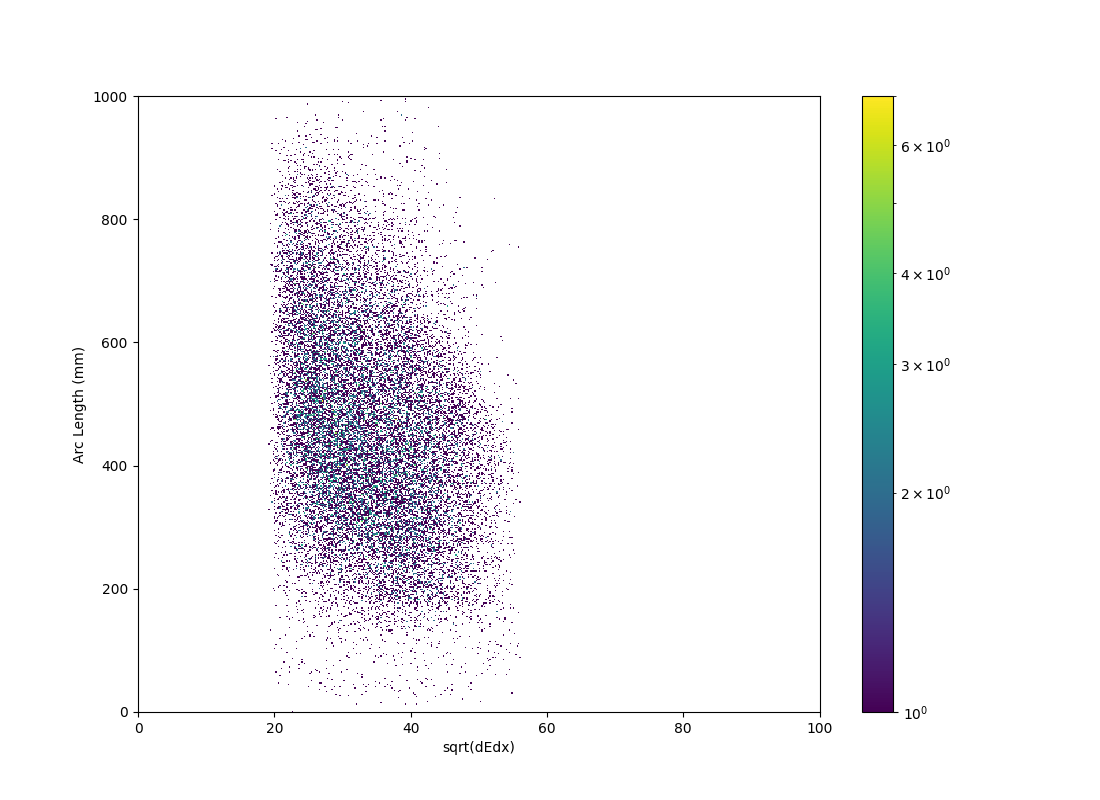

In [28]:
kine = grammer.get_hist2d("arclength_gated")
fig, ax = plt.subplots(1,1)
mesh = ax.pcolormesh(kine.x_bins, kine.y_bins, kine.counts, norm="log")
fig.colorbar(mesh, ax=ax)
# ax.set_title()
ax.set_ylabel("Arc Length (mm)")
ax.set_xlabel("sqrt(dEdx)")
fig.set_figheight(8.0)
fig.set_figwidth(11.0)
# ax.set_xlim([90,180])
fig.savefig("delete1.png")